# Random Walk Hypothesis

> **Note on randomness:** R and NumPy use different pseudo-random number generators, so `np.random.seed(321)` will *not* reproduce R's exact numbers — but the statistical behaviour (shape of paths, test conclusions) matches the R notes closely.

In [76]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams['figure.figsize'] = (8, 5)

# Random Walk with Fixed Moves

Price moves up or down by a fixed amount (5 paisa here) each second, with probability 0.5 / 0.5.

$$P_t = P_{t-1} \pm M_t, \qquad M_t = 5 \text{ a.s. } \forall t$$


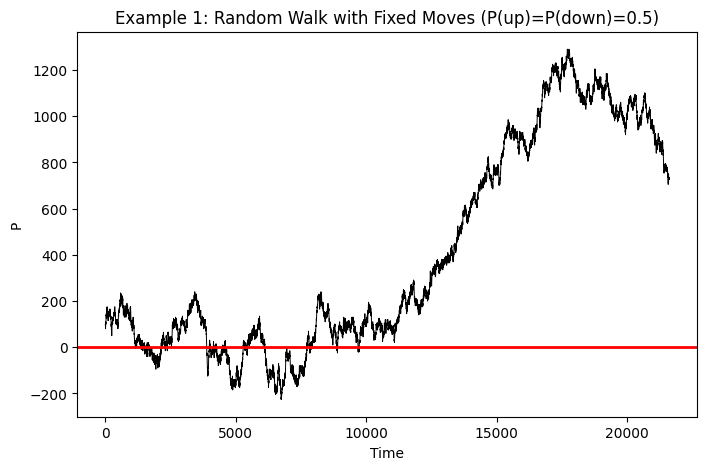

In [77]:
np.random.seed(321)
n = 21600
P = np.full(n, np.nan)
P[0] = 100  # Current price = 100 paisa = Re 1/-

for sec in range(1, n):
    toss = np.random.choice(["H", "T"], p=[0.5, 0.5])
    if toss == "H":
        P[sec] = P[sec - 1] + 5
    else:
        P[sec] = P[sec - 1] - 5

plt.plot(P, color="black", linewidth=0.7)
plt.axhline(y=0, linewidth=2, color="red")
plt.title("Example 1: Random Walk with Fixed Moves (P(up)=P(down)=0.5)")
plt.xlabel("Time"); plt.ylabel("P")
plt.show()

> *"what happens [if the] price of the stock moves up ... with probability 0.51 or moves down ... with probability 0.49 on every second!"*

Biased coin (0.51 up / 0.49 down)
    Theoretical expected total drift over n=21600 secs: 2160.0 paisa
    Simulated final price: 2875.0  (started at 100.0)
    Simulated net change:  2775.0 paisa


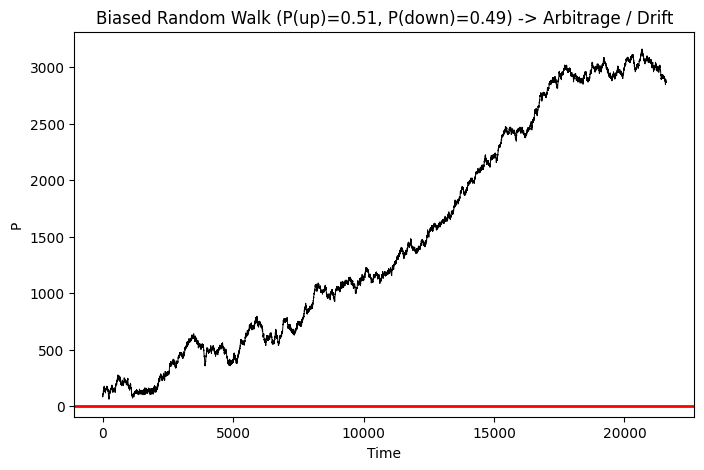

In [78]:
np.random.seed(321)
P_q1 = np.full(n, np.nan)
P_q1[0] = 100

for sec in range(1, n):
    toss = np.random.choice(["H", "T"], p=[0.51, 0.49])  # <-- biased coin
    if toss == "H":
        P_q1[sec] = P_q1[sec - 1] + 5
    else:
        P_q1[sec] = P_q1[sec - 1] - 5

expected_drift = n * (5 * 0.51 - 5 * 0.49)
print("Biased coin (0.51 up / 0.49 down)")
print(f"    Theoretical expected total drift over n={n} secs: {expected_drift:.1f} paisa")
print(f"    Simulated final price: {P_q1[-1]:.1f}  (started at {P_q1[0]:.1f})")
print(f"    Simulated net change:  {P_q1[-1] - P_q1[0]:.1f} paisa")

plt.plot(P_q1, color="black", linewidth=0.7)
plt.axhline(y=0, linewidth=2, color="red")
plt.title("Biased Random Walk (P(up)=0.51, P(down)=0.49) -> Arbitrage / Drift")
plt.xlabel("Time"); plt.ylabel("P")
plt.show()

# Random Walk with Random Moves

Direction is still a fair coin flip, but the **size** of each move is random, $M_t \sim \text{Poisson}(\lambda=5)$.

$$P_t = P_{t-1} \pm M_t, \qquad M_t \sim \text{Poisson}(\lambda=5)$$

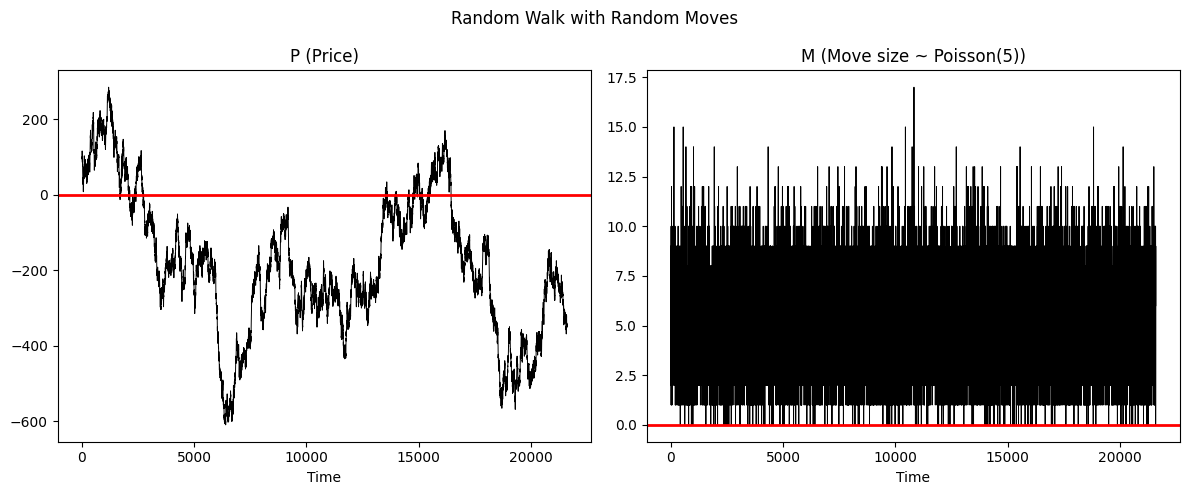

In [79]:
np.random.seed(321)
P2 = np.full(n, np.nan)
M2 = np.full(n, np.nan)
P2[0] = 100

for sec in range(1, n):
    toss = np.random.choice(["H", "T"], p=[0.5, 0.5])
    M2[sec] = np.random.poisson(lam=5)
    if toss == "H":
        P2[sec] = P2[sec - 1] + M2[sec]
    else:
        P2[sec] = P2[sec - 1] - M2[sec]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(P2, color="black", linewidth=0.7)
axes[0].axhline(y=0, linewidth=2, color="red")
axes[0].set_title("P (Price)"); axes[0].set_xlabel("Time")
axes[1].plot(M2, color="black", linewidth=0.7)
axes[1].axhline(y=0, linewidth=2, color="red")
axes[1].set_title("M (Move size ~ Poisson(5))"); axes[1].set_xlabel("Time")
fig.suptitle("Random Walk with Random Moves")
plt.tight_layout()
plt.show()

# Random Walk with Random (Simple) Return

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} \;\Rightarrow\; P_t = P_{t-1}(1+R_t), \qquad R_t \sim N(\mu=0, \sigma=0.01)$$

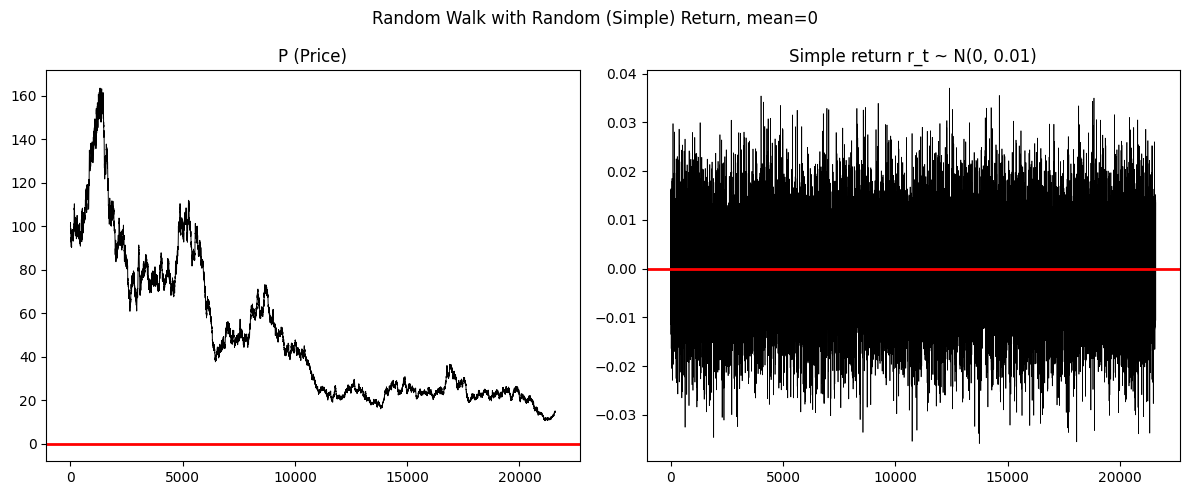

In [80]:
np.random.seed(321)
P3 = np.full(n, np.nan)
P3[0] = 100
rt3 = np.random.normal(loc=0, scale=0.01, size=n)

for sec in range(1, n):
    P3[sec] = P3[sec - 1] * (1 + rt3[sec])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(P3, color="black", linewidth=0.7)
axes[0].axhline(y=0, linewidth=2, color="red")
axes[0].set_title("P (Price)")
axes[1].plot(rt3, color="black", linewidth=0.5)
axes[1].axhline(y=0, linewidth=2, color="red")
axes[1].set_title("Simple return r_t ~ N(0, 0.01)")
fig.suptitle("Random Walk with Random (Simple) Return, mean=0")
plt.tight_layout()
plt.show()

> *"what happend if you choose mean = 0.01 !"*

Simple return with mean = 0.01 (instead of 0)
    Theoretical P0*(1.01)^n  (order of magnitude): 2.196e+95
    Simulated final price after n=21600 secs:        3.341e+94
    -> explosive, unbounded compounding growth: a non-zero mean
       return is itself an arbitrage opportunity.


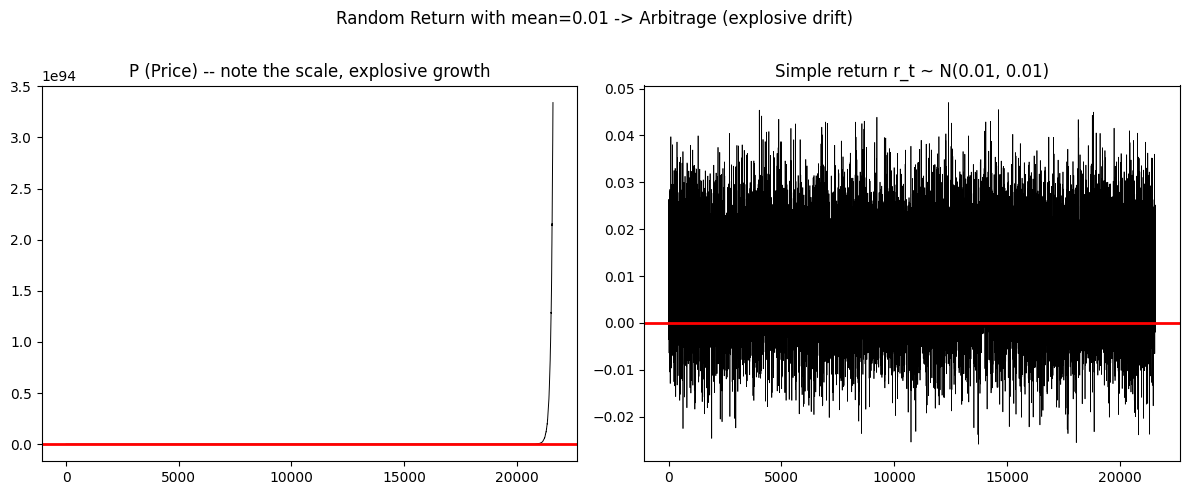

In [81]:
np.random.seed(321)
P3b = np.full(n, np.nan)
P3b[0] = 100
rt3b = np.random.normal(loc=0.01, scale=0.01, size=n)

for sec in range(1, n):
    P3b[sec] = P3b[sec - 1] * (1 + rt3b[sec])

theoretical_growth = P3b[0] * (1.01 ** n)
print("Simple return with mean = 0.01 (instead of 0)")
print(f"    Theoretical P0*(1.01)^n  (order of magnitude): {theoretical_growth:.3e}")
print(f"    Simulated final price after n={n} secs:        {P3b[-1]:.3e}")
print("    -> explosive, unbounded compounding growth: a non-zero mean")
print("       return is itself an arbitrage opportunity.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(P3b, color="black", linewidth=0.7)
axes[0].axhline(y=0, linewidth=2, color="red")
axes[0].set_title("P (Price) -- note the scale, explosive growth")
axes[1].plot(rt3b, color="black", linewidth=0.5)
axes[1].axhline(y=0, linewidth=2, color="red")
axes[1].set_title("Simple return r_t ~ N(0.01, 0.01)")
fig.suptitle("Random Return with mean=0.01 -> Arbitrage (explosive drift)")
plt.tight_layout()
plt.show()

# Random Walk with Random log-Return

The log-return captures continuous compounding:

$$r_t = \log(P_t) - \log(P_{t-1}) \;\Rightarrow\; P_t = P_{t-1}e^{r_t}, \qquad r_t \sim N(\mu=0, \sigma=0.01)$$

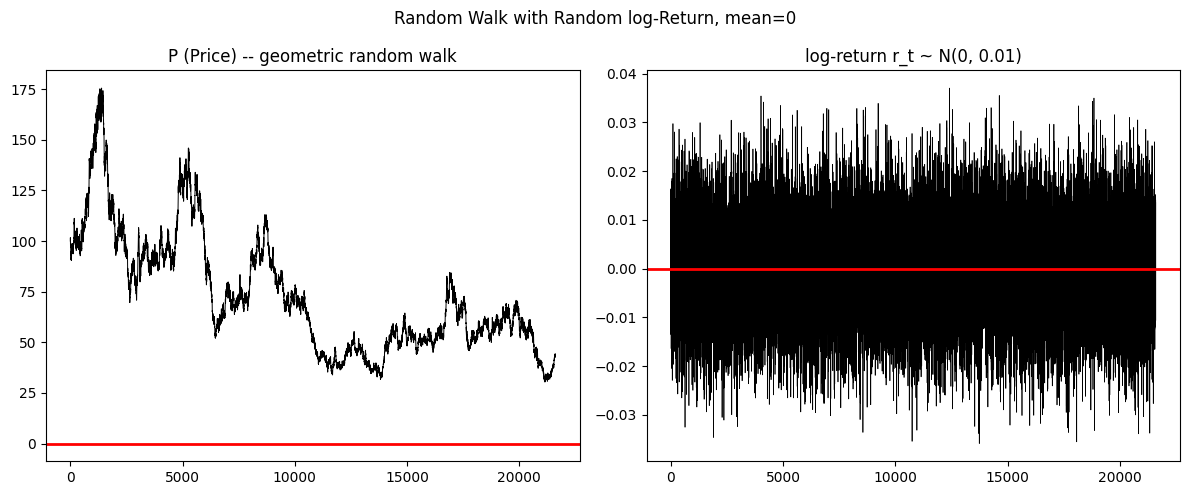

In [82]:
np.random.seed(321)
P4 = np.full(n, np.nan)
P4[0] = 100
rt4 = np.random.normal(loc=0, scale=0.01, size=n)

for sec in range(1, n):
    P4[sec] = P4[sec - 1] * np.exp(rt4[sec])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(P4, color="black", linewidth=0.7)
axes[0].axhline(y=0, linewidth=2, color="red")
axes[0].set_title("P (Price) -- geometric random walk")
axes[1].plot(rt4, color="black", linewidth=0.5)
axes[1].axhline(y=0, linewidth=2, color="red")
axes[1].set_title("log-return r_t ~ N(0, 0.01)")
fig.suptitle("Random Walk with Random log-Return, mean=0")
plt.tight_layout()
plt.show()

# Simulating a Stationary Process, and Building a Random Walk From It

A random walk's **price level** is non-stationary, but its **increments** (steps) can be a stationary process.

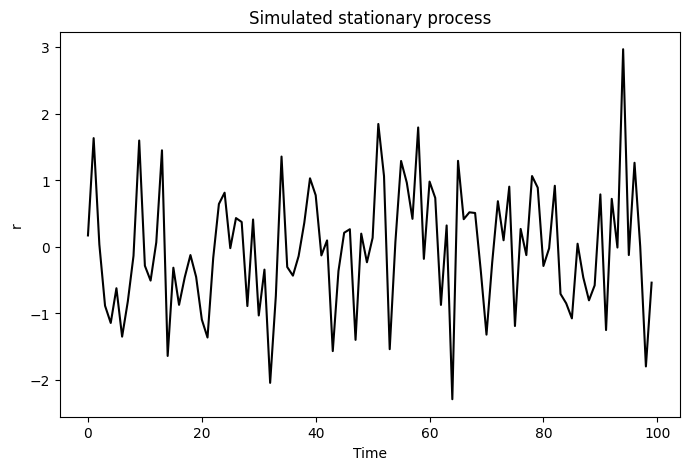

In [83]:
mu, s, n_stat = 0, 1, 100
np.random.seed(321)
r = np.random.normal(mu, s, n_stat)

plt.plot(r, color="black")
plt.title("Simulated stationary process")
plt.xlabel("Time"); plt.ylabel("r")
plt.show()

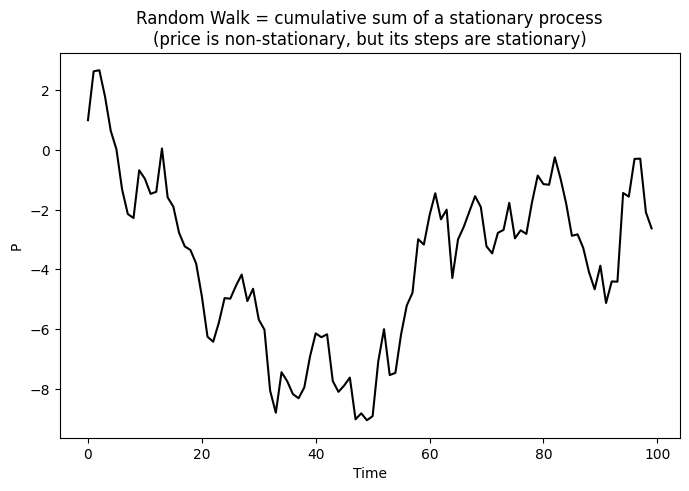

In [84]:
P_cumsum = r.copy()
P_cumsum[0] = 1
P_cumsum = np.cumsum(P_cumsum)

plt.plot(P_cumsum, color="black")
plt.title("Random Walk = cumulative sum of a stationary process\n"
          "(price is non-stationary, but its steps are stationary)")
plt.xlabel("Time"); plt.ylabel("P")
plt.show()

# Dickey-Fuller Test for Stationarity — `EuStockMarkets` Dataset

`EuStockMarkets` is one of R's built-in datasets, not available in any Python package by default. We pull the **identical numbers** from the public *Rdatasets* GitHub mirror (a CSV copy of R's built-in datasets) so the results match exactly.

In [85]:
csv_url = ("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
           "master/csv/datasets/EuStockMarkets.csv")
eu = pd.read_csv(csv_url, index_col=0)
eu.head(6)

,DAX,SMI,CAC,FTSE
rownames,,,,
1,1628.75,1678.1,1772.8,2443.6
2,1613.63,1688.5,1750.5,2460.2
3,1606.51,1678.6,1718.0,2448.2
4,1621.04,1684.1,1708.1,2470.4
5,1618.16,1686.6,1723.1,2484.7
6,1610.61,1671.6,1714.3,2466.8


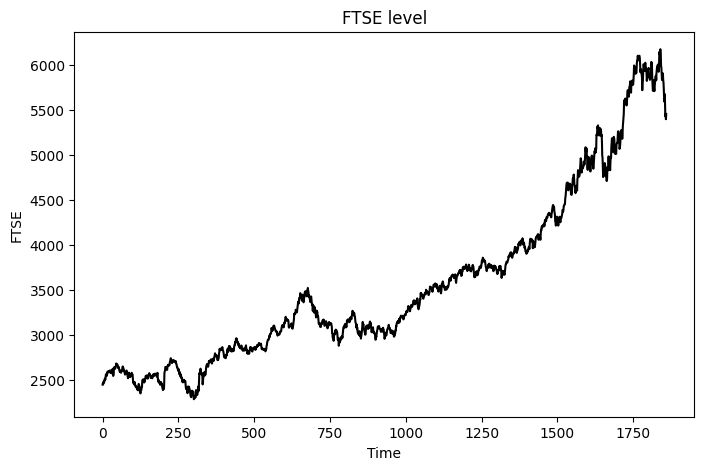

In [86]:
FTSE = eu["FTSE"].to_numpy()
n_ftse = len(FTSE)

plt.plot(FTSE, color="black")
plt.grid(color="white", linestyle="--", alpha=0.6)
plt.title("FTSE level")
plt.xlabel("Time"); plt.ylabel("FTSE")
plt.show()

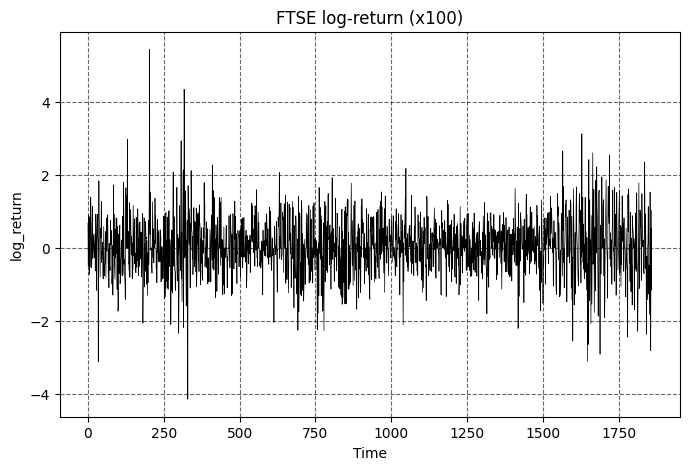

In [87]:
log_return = np.diff(np.log(FTSE)) * 100
n_lr = len(log_return)

plt.plot(log_return, color="black", linewidth=0.5)
plt.grid(color="black", linestyle="--", alpha=0.6)
plt.title("FTSE log-return (x100)")
plt.xlabel("Time"); plt.ylabel("log_return")
plt.show()

# Augmented Dickey-Fuller Test

> Note: the *p-values* won't match exactly — R's `tseries` interpolates a finite-sample table, while `statsmodels` uses MacKinnon's asymptotic approximation — but the statistic, lag order, and conclusion all match.

In [88]:
n_logp = len(np.log(FTSE))
k1 = int((n_logp - 1) ** (1 / 3))
adf_price = adfuller(np.log(FTSE), maxlag=k1, autolag=None, regression="ct")

print("ADF test on log(FTSE)  [H0: unit root / non-stationary]")
print(f"    Dickey-Fuller statistic = {adf_price[0]:.4f}, Lag order = {adf_price[2]}, "
      f"p-value = {adf_price[1]:.4f}")
print("    -> high p-value: FAIL to reject H0, log(FTSE) is non-stationary "
      "(matches R: DF=-2.4976, Lag=12, p=0.3677)")

ADF test on log(FTSE)  [H0: unit root / non-stationary]
    Dickey-Fuller statistic = -2.4976, Lag order = 12, p-value = 0.3292
    -> high p-value: FAIL to reject H0, log(FTSE) is non-stationary (matches R: DF=-2.4976, Lag=12, p=0.3677)


In [89]:
n_lr2 = len(log_return)
k2 = int((n_lr2 - 1) ** (1 / 3))
adf_logret = adfuller(log_return, maxlag=k2, autolag=None, regression="ct")

print("ADF test on log_return  [H0: unit root / non-stationary]")
print(f"    Dickey-Fuller statistic = {adf_logret[0]:.4f}, Lag order = {adf_logret[2]}, "
      f"p-value = {adf_logret[1]:.4g}")
print("    -> very low p-value: REJECT H0, log-return IS stationary "
      "(matches R: DF=-11.162, Lag=12, p<=0.01)")

ADF test on log_return  [H0: unit root / non-stationary]
    Dickey-Fuller statistic = -11.1622, Lag order = 12, p-value = 1.103e-17
    -> very low p-value: REJECT H0, log-return IS stationary (matches R: DF=-11.162, Lag=12, p<=0.01)


# Ljung-Box Test for Independence


In [90]:
lb = acorr_ljungbox(log_return, lags=[10], return_df=True)
print("Ljung-Box test on log_return  [H0: rho_1=...=rho_10=0, no autocorrelation]")
print(lb)
print(f"\n    -> p-value = {lb['lb_pvalue'].iloc[0]:.6f} "
      "(matches R exactly: X-squared=29.815, df=10, p=0.0009183)")

Ljung-Box test on log_return  [H0: rho_1=...=rho_10=0, no autocorrelation]
      lb_stat  lb_pvalue
10  29.815414   0.000918

    -> p-value = 0.000918 (matches R exactly: X-squared=29.815, df=10, p=0.0009183)


**Conclusion:** We REJECT $H_0$ — the log-returns show significant serial correlation, so the (weak-form) market-efficiency / random-walk hypothesis for raw FTSE returns is questionable here, even though the returns are individually stationary.